# Black-Litterman: una opinión bien ponderada frente a una opinión tomada al pie de la letra

**Perfil:** Gestión de portafolios  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Un gestor tiene **opiniones** sobre algunos activos. Si las trata como pronósticos exactos, el optimizador produce posiciones extremas. Black-Litterman las **mezcla** con el equilibrio de mercado según su confianza. ¿Esa mezcla es correcta? ¿Cuánto vale tener la confianza bien calibrada, y qué cuesta equivocarse?

## Recorrido

1. Equilibrio de mercado (optimización inversa), opiniones y la fórmula posterior.
2. **Versión 1:** opiniones tomadas como ciertas. **Versión 2:** Black-Litterman con confianza explícita.
3. **Verificación bayesiana:** la fórmula coincide con una simulación del propio modelo.
4. **Propiedades:** sin opiniones, mercado; confianza infinita, opinión exacta; el tilt vive en el espacio de las opiniones; τ se cancela con la parametrización de He-Litterman.
5. **Valor de la calibración:** utilidad verdadera con confianza correcta, sobreconfiada y subconfiada.
6. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy.optimize import minimize

## 2. El equilibrio de mercado

Si el mercado está en equilibrio y los inversionistas son de media-varianza con aversión al riesgo $\delta$, los **retornos implícitos** que justifican los pesos de capitalización $w_{\text{mkt}}$ son
$$\pi=\delta\,\Sigma\,w_{\text{mkt}}.$$
Es la **optimización inversa**: en lugar de partir de retornos esperados (que no se conocen) se parte de los pesos del mercado (que sí se observan). Se verifica que optimizar con $\pi$ devuelve $w_{\text{mkt}}$.

In [2]:
ACT = ["EEUU", "Europa", "Japon", "Emergentes", "Bonos", "Inmobiliario"]
N_A = len(ACT)
W_MKT = np.array([0.34, 0.15, 0.08, 0.10, 0.28, 0.05])
VOL = np.array([0.16, 0.18, 0.17, 0.23, 0.06, 0.19])
CORR = np.array([[1.00, 0.82, 0.62, 0.70, 0.00, 0.60],
                 [0.82, 1.00, 0.64, 0.72, 0.05, 0.58],
                 [0.62, 0.64, 1.00, 0.60, 0.05, 0.50],
                 [0.70, 0.72, 0.60, 1.00, 0.00, 0.55],
                 [0.00, 0.05, 0.05, 0.00, 1.00, 0.20],
                 [0.60, 0.58, 0.50, 0.55, 0.20, 1.00]])
assert np.all(np.linalg.eigvalsh(CORR) > 0)
SIGMA = np.outer(VOL, VOL) * CORR
DELTA = 2.5
PI = DELTA * SIGMA @ W_MKT

# verificacion: la optimizacion media-varianza sin restricciones con pi devuelve los pesos de mercado
w_inv = np.linalg.solve(DELTA * SIGMA, PI)
assert np.allclose(w_inv, W_MKT), "optimizar con los retornos implicitos debe devolver el portafolio de mercado"
print(pd.DataFrame({"peso_mercado": W_MKT, "vol": VOL, "retorno_implicito": PI}, index=ACT).round(4).to_string())
print("\nVerificacion: w = (delta*Sigma)^-1 * pi reproduce los pesos de mercado (max error", np.abs(w_inv - W_MKT).max(), ")")

              peso_mercado    vol  retorno_implicito
EEUU                0.3400 0.1600             0.0427
Europa              0.1500 0.1800             0.0464
Japon               0.0800 0.1700             0.0357
Emergentes          0.1000 0.2300             0.0540
Bonos               0.2800 0.0600             0.0031
Inmobiliario        0.0500 0.1900             0.0383

Verificacion: w = (delta*Sigma)^-1 * pi reproduce los pesos de mercado (max error 2.7755575615628914e-16 )


## 3. Las opiniones

Dos opiniones del gestor, expresadas como combinaciones lineales $P\mu=Q$:

1. **Relativa:** Emergentes **superan** a EEUU en 4 puntos porcentuales anuales.
2. **Absoluta:** Europa rinde **9 %** anual (el equilibrio implícito es menor).

In [3]:
P = np.array([[-1, 0, 0, 1, 0, 0],
              [0, 1, 0, 0, 0, 0]], dtype=float)
Q = np.array([0.04, 0.09])
print("Retornos implicitos que corresponden a las opiniones: P @ pi =", (P @ PI).round(4), "| opinion Q =", Q)
print("Diferencia (opinion - equilibrio):", (Q - P @ PI).round(4))

Retornos implicitos que corresponden a las opiniones: P @ pi = [0.0113 0.0464] | opinion Q = [0.04 0.09]
Diferencia (opinion - equilibrio): [0.0287 0.0436]


## 4. Versión 1: tomar las opiniones como ciertas

Se resuelve el problema media-varianza con retornos $\mu$ **forzados** a cumplir las opiniones exactamente (la solución de mínima desviación respecto del equilibrio con $P\mu=Q$):
$$\mu_{\text{ingenuo}}=\pi+\Sigma P^\top (P\Sigma P^\top)^{-1}(Q-P\pi).$$
Es el límite de confianza total $\Omega\to0$.

In [4]:
mu_ing = PI + SIGMA @ P.T @ np.linalg.solve(P @ SIGMA @ P.T, Q - P @ PI)
w_ing = np.linalg.solve(DELTA * SIGMA, mu_ing)
pd.DataFrame({"mercado": W_MKT, "opiniones como ciertas": w_ing, "diferencia": w_ing - W_MKT}, index=ACT).round(3)

,mercado,opiniones como ciertas,diferencia
EEUU,0.3400,0.0240,-0.3160
Europa,0.1500,0.6270,0.4770
Japon,0.0800,0.0800,-0.0000
Emergentes,0.1000,0.4160,0.3160
Bonos,0.2800,0.2800,0.0000
Inmobiliario,0.0500,0.0500,-0.0000


In [5]:
print("Lectura:")
print(f"  Con las opiniones tomadas como ciertas, los pesos se desvian del mercado hasta {np.abs(w_ing - W_MKT).max():.2f} en un solo activo (rotacion total {0.5 * np.abs(w_ing - W_MKT).sum():.2f}).")
print(f"  Pesos extremos o negativos: {[a for a, w in zip(ACT, w_ing) if w < 0 or w > 0.6] or 'ninguno'}")

Lectura:
  Con las opiniones tomadas como ciertas, los pesos se desvian del mercado hasta 0.48 en un solo activo (rotacion total 0.55).
  Pesos extremos o negativos: ['Europa']


## 5. Versión 2: Black-Litterman

Se trata el equilibrio como un **prior**: $\mu\sim N(\pi,\tau\Sigma)$ ($\tau$ es la incertidumbre sobre el equilibrio) y las opiniones como **observaciones ruidosas**: $Q=P\mu+\varepsilon$, $\varepsilon\sim N(0,\Omega)$. La media posterior es
$$\mu_{BL}=\pi+\tau\Sigma P^\top\big(P\tau\Sigma P^\top+\Omega\big)^{-1}(Q-P\pi),\qquad w_{BL}=(\delta\Sigma)^{-1}\mu_{BL}.$$
Falta definir $\Omega$. Con la parametrización de **He y Litterman**, $\Omega=\kappa\,\mathrm{diag}(P\tau\Sigma P^\top)$: $\kappa$ pequeño = mucha confianza; $\kappa=1$ = la opinión pesa igual que el prior.

In [6]:
TAU = 0.05

def bl(P, Q, Omega, tau=TAU, pi=PI, S=SIGMA):
    A = np.linalg.inv(P @ (tau * S) @ P.T + Omega)
    mu = pi + tau * S @ P.T @ A @ (Q - P @ pi)
    return mu, np.linalg.solve(DELTA * S, mu)

def omega_hl(P, kappa, tau=TAU, S=SIGMA):
    return kappa * np.diag(np.diag(P @ (tau * S) @ P.T))

tabla = {"mercado": W_MKT, "opiniones ciertas": w_ing}
for kappa in (0.1, 1.0, 4.0):
    mu_b, w_b = bl(P, Q, omega_hl(P, kappa)); tabla[f"BL kappa={kappa}"] = w_b
res_w = pd.DataFrame(tabla, index=ACT)
res_w.round(3)

,mercado,opiniones ciertas,BL kappa=0.1,BL kappa=1.0,BL kappa=4.0
EEUU,0.3400,0.0240,0.0440,0.1560,0.2600
Europa,0.1500,0.6270,0.5870,0.4010,0.2540
Japon,0.0800,0.0800,0.0800,0.0800,0.0800
Emergentes,0.1000,0.4160,0.3960,0.2840,0.1800
Bonos,0.2800,0.2800,0.2800,0.2800,0.2800
Inmobiliario,0.0500,0.0500,0.0500,0.0500,0.0500


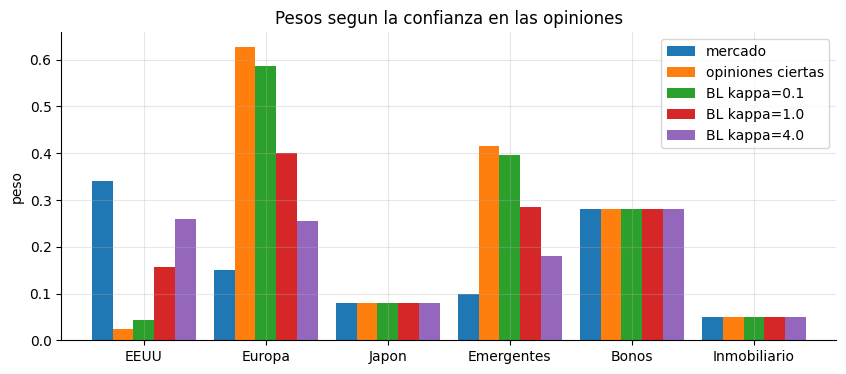

Lectura: rotacion respecto del mercado (L1/2):
  opiniones ciertas   : 0.555
  BL kappa=0.1        : 0.514
  BL kappa=1.0        : 0.310
  BL kappa=4.0        : 0.133
  La confianza (kappa) regula de forma continua entre 'ignorar la opinion' (kappa grande) y 'tomarla como cierta' (kappa -> 0).


In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
res_w.plot(kind="bar", ax=ax, width=0.85); ax.axhline(0, color="k", lw=0.6); ax.set_ylabel("peso"); ax.set_title("Pesos segun la confianza en las opiniones"); plt.xticks(rotation=0); plt.show()
print("Lectura: rotacion respecto del mercado (L1/2):")
for k in res_w.columns[1:]:
    print(f"  {k:20s}: {0.5 * np.abs(res_w[k] - W_MKT).sum():.3f}")
print("  La confianza (kappa) regula de forma continua entre 'ignorar la opinion' (kappa grande) y 'tomarla como cierta' (kappa -> 0).")

## 6. Verificación: ¿la fórmula es realmente la media posterior?

Es una afirmación **comprobable**. Si se simula el propio modelo bayesiano —se sortea $\mu\sim N(\pi,\tau\Sigma)$ y luego $Q=P\mu+\varepsilon$— entonces $\mathbb{E}[\mu\mid Q]$ debe coincidir con la fórmula. Se estima por **regresión lineal** de $\mu$ sobre $Q$ en 400.000 sorteos y se compara con los coeficientes de la fórmula.

In [8]:
rg = np.random.default_rng(1)
n_sim = 400_000
Om = omega_hl(P, 1.0)
mu_sorteo = rg.multivariate_normal(PI, TAU * SIGMA, n_sim)
Q_sorteo = mu_sorteo @ P.T + rg.multivariate_normal(np.zeros(2), Om, n_sim)

# coeficientes de la media posterior segun la formula: E[mu|Q] = pi + K (Q - P pi), K = tau Sigma P' (P tau Sigma P' + Omega)^-1
K_formula = TAU * SIGMA @ P.T @ np.linalg.inv(P @ (TAU * SIGMA) @ P.T + Om)
# estimacion por minimos cuadrados: mu - pi ~ K (Q - P pi)
X_ = Q_sorteo - P @ PI; Y_ = mu_sorteo - PI
K_emp = np.linalg.lstsq(X_, Y_, rcond=None)[0].T
print("max |K_formula - K_empirica| =", np.abs(K_formula - K_emp).max().round(5), "(error de simulacion esperado ~", (1 / np.sqrt(n_sim)).round(4), ")")
# y el error cuadratico medio de la media posterior es el minimo posible: menor que el de usar solo el prior
mu_post = PI + X_ @ K_formula.T
print(f"ECM de la media posterior: {np.mean((mu_post - mu_sorteo) ** 2):.6f} | ECM de usar solo el prior (pi): {np.mean((PI - mu_sorteo) ** 2):.6f}")

max |K_formula - K_empirica| = 0.00269 (error de simulacion esperado ~ 0.0016 )
ECM de la media posterior: 0.000974 | ECM de usar solo el prior (pi): 0.001491


## 7. Propiedades del modelo (verificadas numéricamente)

1. **Sin opiniones, mercado:** si $\Omega\to\infty$ (confianza nula), $w_{BL}=w_{\text{mkt}}$.
2. **Confianza infinita, opinión exacta:** si $\Omega\to0$, $P\mu_{BL}=Q$ y $w_{BL}=w_{\text{ingenuo}}$.
3. **El tilt vive en el espacio de las opiniones:** $w_{BL}-w_{\text{mkt}}=\tfrac1\delta P^\top(P\Sigma P^\top+\Omega/\tau)^{-1}(Q-P\pi)$ está en el subespacio generado por las filas de $P$.
4. **$\tau$ se cancela** con la parametrización de He-Litterman ($\Omega\propto\tau$): la media posterior no depende de $\tau$.

In [9]:
# 1) confianza nula
mu0, w0 = bl(P, Q, np.eye(2) * 1e12); d1 = np.abs(w0 - W_MKT).max()
# 2) confianza infinita
mu_inf, w_inf = bl(P, Q, np.eye(2) * 1e-12); d2 = np.abs(P @ mu_inf - Q).max(); d2b = np.abs(w_inf - w_ing).max()
# 3) el tilt esta en el espacio de las filas de P
mu_k, w_k = bl(P, Q, omega_hl(P, 1.0)); tilt = w_k - W_MKT
coef, *_ = np.linalg.lstsq(P.T, tilt, rcond=None); resid_tilt = np.abs(P.T @ coef - tilt).max()
# 4) tau se cancela con Omega = kappa * diag(P tau Sigma P')
mus = [bl(P, Q, omega_hl(P, 1.0, tau=t), tau=t)[0] for t in (0.01, 0.05, 0.25, 1.0)]
d4 = max(np.abs(m - mus[0]).max() for m in mus)
# 4b) con Omega FIJO (no proporcional a tau), la media si depende de tau
mus_fijo = [bl(P, Q, omega_hl(P, 1.0, tau=0.05), tau=t)[0] for t in (0.01, 0.05, 0.25, 1.0)]
d4b = max(np.abs(m - mus_fijo[0]).max() for m in mus_fijo)
print(f"1) confianza nula:   max|w_BL - w_mercado| = {d1:.2e}")
print(f"2) confianza infinita: max|P mu_BL - Q| = {d2:.2e} | max|w_BL - w_opiniones_ciertas| = {d2b:.2e}")
print(f"3) el tilt es combinacion lineal de las filas de P: residuo = {resid_tilt:.2e}")
print(f"4) tau cancelado con Omega=kappa*diag(P tau Sigma P'): variacion de mu_BL entre tau en [0.01, 1] = {d4:.2e}")
print(f"4b) con Omega FIJO la media depende de tau: variacion = {d4b:.4f}")

1) confianza nula:   max|w_BL - w_mercado| = 1.08e-15
2) confianza infinita: max|P mu_BL - Q| = 2.39e-11 | max|w_BL - w_opiniones_ciertas| = 2.61e-10
3) el tilt es combinacion lineal de las filas de P: residuo = 4.44e-16
4) tau cancelado con Omega=kappa*diag(P tau Sigma P'): variacion de mu_BL entre tau en [0.01, 1] = 1.39e-17
4b) con Omega FIJO la media depende de tau: variacion = 0.0436


## 8. ¿Cuánto vale tener la confianza bien calibrada?

Se simula un **mundo con verdad conocida**: en cada una de 2.000 réplicas se sortea el retorno esperado verdadero $\mu\sim N(\pi,\tau_t\Sigma)$ y el gestor recibe opiniones ruidosas $Q=P\mu+\varepsilon$ con $\varepsilon\sim N(0,\Omega_{\text{ver}})$, $\Omega_{\text{ver}}=\kappa_{\text{ver}}\,\mathrm{diag}(P\tau_t\Sigma P^\top)$. Se evalúa cada estrategia con la **utilidad verdadera** $U=w^\top\mu-\tfrac\delta2 w^\top\Sigma w$, relativa a la del mercado.

Estrategias: **mercado**; **opiniones ciertas** ($\kappa\to0$); **BL calibrado** (el $\kappa$ declarado es el verdadero); **BL sobreconfiado** (declara $\kappa/10$) y **BL subconfiado** (declara $10\kappa$).

In [10]:
TAU_T = 0.05
def utilidad(w, mu): return w @ mu - 0.5 * DELTA * w @ SIGMA @ w

def experimento(kappa_ver, R=2000, seed=0):
    rg = np.random.default_rng(seed)
    mu = rg.multivariate_normal(PI, TAU_T * SIGMA, R)
    Om_ver = omega_hl(P, kappa_ver, tau=TAU_T)
    Qs = mu @ P.T + rg.multivariate_normal(np.zeros(2), Om_ver, R)
    estrategias = {"mercado": None, "opiniones ciertas": 1e-9, "BL sobreconfiado (k/10)": kappa_ver / 10, "BL calibrado": kappa_ver, "BL subconfiado (10k)": kappa_ver * 10}
    out = {k: [] for k in estrategias}
    for i in range(R):
        for k, kap in estrategias.items():
            if kap is None: w = W_MKT
            else: w = bl(P, Qs[i], omega_hl(P, kap, tau=TAU_T), tau=TAU_T)[1]
            out[k].append(utilidad(w, mu[i]))
    u = pd.DataFrame(out); return u.sub(u["mercado"], axis=0)

tabla = {}
for kap in (0.25, 1.0, 4.0, 16.0):
    ex = experimento(kap, seed=int(kap * 10))
    tabla[kap] = ex.mean().drop("mercado")
ganancia = pd.DataFrame(tabla).T; ganancia.index.name = "ruido_verdadero_kappa"
(ganancia * 1e4).round(2)    # puntos base de utilidad sobre el mercado

,opiniones ciertas,BL sobreconfiado (k/10),BL calibrado,BL subconfiado (10k)
ruido_verdadero_kappa,,,,
0.2500,156.4700,159.1600,167.7100,97.2500
1.0000,-29.1800,10.1400,89.3900,31.0400
4.0000,-634.1600,-217.6700,45.9500,10.0500
16.0000,"-3,232.6700",-356.2100,11.2600,2.3300


In [11]:
print("Lectura: utilidad adicional sobre el mercado, en puntos base (x1e4), por ruido verdadero kappa de las opiniones:")
for kap in ganancia.index:
    f = ganancia.loc[kap] * 1e4
    mejor = f.idxmax(); print(f"  kappa={kap:<5} -> mejor: {mejor} ({f.max():.1f}); calibrado {f['BL calibrado']:.1f} | sobreconfiado {f['BL sobreconfiado (k/10)']:.1f} | opiniones ciertas {f['opiniones ciertas']:.1f}")
neg = [(kap, c) for kap in ganancia.index for c in ganancia.columns if ganancia.loc[kap, c] < 0]
print(f"  Casos en que una estrategia rinde MENOS que el mercado: {neg if neg else 'ninguno'}")

Lectura: utilidad adicional sobre el mercado, en puntos base (x1e4), por ruido verdadero kappa de las opiniones:
  kappa=0.25  -> mejor: BL calibrado (167.7); calibrado 167.7 | sobreconfiado 159.2 | opiniones ciertas 156.5
  kappa=1.0   -> mejor: BL calibrado (89.4); calibrado 89.4 | sobreconfiado 10.1 | opiniones ciertas -29.2
  kappa=4.0   -> mejor: BL calibrado (46.0); calibrado 46.0 | sobreconfiado -217.7 | opiniones ciertas -634.2
  kappa=16.0  -> mejor: BL calibrado (11.3); calibrado 11.3 | sobreconfiado -356.2 | opiniones ciertas -3232.7
  Casos en que una estrategia rinde MENOS que el mercado: [(1.0, 'opiniones ciertas'), (4.0, 'opiniones ciertas'), (4.0, 'BL sobreconfiado (k/10)'), (16.0, 'opiniones ciertas'), (16.0, 'BL sobreconfiado (k/10)')]


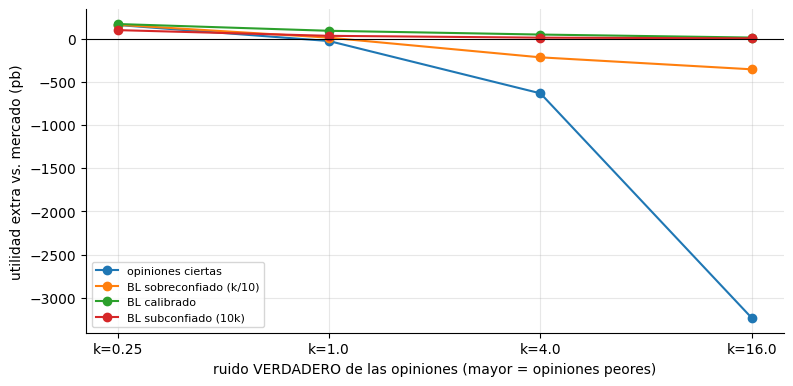

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for c in ganancia.columns: ax.plot(range(len(ganancia)), ganancia[c] * 1e4, "o-", label=c)
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(len(ganancia))); ax.set_xticklabels([f"k={k}" for k in ganancia.index])
ax.set_xlabel("ruido VERDADERO de las opiniones (mayor = opiniones peores)"); ax.set_ylabel("utilidad extra vs. mercado (pb)"); ax.legend(fontsize=8); plt.show()

**Qué se aprende.** Con la confianza **calibrada**, Black-Litterman es **óptimo** (es la media posterior): ninguna otra estrategia obtiene mayor utilidad esperada con la misma información. Declarar **más** confianza de la que se tiene (sobreconfianza) pierde utilidad, y en el límite (tomar la opinión como cierta) puede quedar **por debajo del mercado** cuando las opiniones son ruidosas. Declarar **menos** confianza es más seguro pero desaprovecha información.

## 9. Pruebas automáticas

In [13]:
# 9.1 la optimizacion inversa devuelve el mercado
assert np.allclose(w_inv, W_MKT)
# 9.2 las propiedades limite: confianza nula = mercado; confianza infinita = opinion exacta = opiniones ciertas
assert d1 < 1e-6 and d2 < 1e-6 and d2b < 1e-5
# 9.3 el tilt vive en el espacio de las opiniones
assert resid_tilt < 1e-9
# 9.4 tau se cancela con la parametrizacion de He-Litterman y NO con Omega fijo
assert d4 < 1e-9 and d4b > 1e-4
# 9.5 la formula es la media posterior (regresion sobre la simulacion bayesiana) y reduce el ECM frente al prior
assert np.abs(K_formula - K_emp).max() < 0.01
assert np.mean((mu_post - mu_sorteo) ** 2) < np.mean((PI - mu_sorteo) ** 2)
# 9.6 con opiniones tomadas como ciertas los pesos se desvian mas del mercado que con BL calibrado
assert 0.5 * np.abs(w_ing - W_MKT).sum() > 0.5 * np.abs(res_w["BL kappa=1.0"] - W_MKT).sum() > 0.5 * np.abs(res_w["BL kappa=4.0"] - W_MKT).sum()
# 9.7 el BL calibrado es optimo: gana a sobreconfiado, subconfiado y opiniones ciertas en cada nivel de ruido verdadero
for kap in ganancia.index:
    assert ganancia.loc[kap, "BL calibrado"] >= ganancia.loc[kap].drop("BL calibrado").max() - 2e-5, f"BL calibrado no es el mejor con kappa={kap}"
# 9.8 el BL calibrado nunca rinde menos que el mercado (es Bayes-optimo); tomar las opiniones como ciertas si puede quedar por debajo
assert (ganancia["BL calibrado"] > -1e-5).all()
assert ganancia.loc[16.0, "opiniones ciertas"] < 0 and ganancia.loc[16.0, "opiniones ciertas"] < ganancia.loc[16.0, "BL calibrado"]
# 9.9 la ganancia del BL calibrado cae al empeorar las opiniones
assert ganancia["BL calibrado"].is_monotonic_decreasing
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| v1: opiniones ciertas | Pesos extremos, grandes desvíos del mercado y utilidad por debajo del mercado si las opiniones son ruidosas | Nunca tratar una opinión como pronóstico exacto |
| v2: Black-Litterman | Mezcla equilibrio y opiniones según la confianza declarada (κ); sin opiniones, mercado | Declarar la confianza de forma explícita |
| Verificación bayesiana | La fórmula coincide con la regresión sobre la simulación del propio modelo | Comprobar fórmulas contra simulación |
| Propiedades | El tilt vive en el espacio de las opiniones; τ se cancela con Ω ∝ τ pero no con Ω fijo | Parametrizar Ω en proporción a τΣ para que τ no sea un parámetro oculto |
| Valor de la calibración | Con la confianza correcta, BL es óptimo; sobreconfiar daña y tomar la opinión como cierta puede rendir menos que el mercado | Calibrar κ con el historial de aciertos del gestor |

**Límites que no deben ocultarse**

- El modelo supone que el prior de retornos es N(π, τΣ) y que el ruido de las opiniones es gaussiano e independiente; en la práctica ambos son aproximaciones.
- Los pesos de equilibrio se suponen observables y el mercado en equilibrio; si el mercado no está en equilibrio, el prior está sesgado.
- La calibración se evalúa con una verdad simulada del propio modelo, lo que favorece a BL; con un mundo distinto (opiniones sesgadas, no ruidosas) la ventaja podría ser menor.
- Se trabaja sin restricciones (posiciones cortas permitidas); con restricciones largo-solo los pesos pueden quedar en los topes.
- Datos sintéticos: ningún valor numérico es extrapolable a una cartera real.